# 08 · ShellScope Ownership Network (Network Analysis Days 1–5)

**Question:** do companies cluster around shared addresses and owners, and do linked groups, loops and deep chains carry more risk?

| Part | Day | Graph | Output |
|---|---|---|---|
| 1 | 1 | Glasgow companies ↔ addresses (bipartite) | nodes, edges, components |
| 2 | 2 | + owners (people as hashed IDs, companies by name) | `results/network_hubs.csv` (private) |
| 3 | 3 | UK-wide owner company → owned company (directed) | cycles, chain depth, `reports/figures/net_chain_depth.png` |
| 4 | 4 | Louvain communities on the Glasgow graph | `results/network_communities.csv`, 2 network PNGs |
| 5 | 5 | Network measures → columns | `network_features`, `risk_flags_network`, README section |

**Privacy rules:** individuals appear only as a hashed ID and are never labelled. Files that name addresses or owners stay in `results/` and are **gitignored**. Network pictures carry no labels.

⚠️ Close `07_sql_core.ipynb` first (`con.close()` or shut its kernel down): only one notebook can open the database.

## 0. Setup

In [1]:
import duckdb, pandas as pd, numpy as np, networkx as nx, matplotlib.pyplot as plt
import time, json, zipfile, hashlib
from itertools import islice
from pathlib import Path

ROOT    = Path("/Users/shraddha/Documents/DATA_SCIENCE/Shellscope/shellscope")
DB      = ROOT / "data" / "shellscope.duckdb"
PSC_DIR = ROOT / "data" / "raw" / "psc"
RESULTS = ROOT / "results"
FIG     = ROOT / "reports" / "figures"
SQL_DIR = ROOT / "sql"
for d in (RESULTS, FIG, SQL_DIR):
    d.mkdir(parents=True, exist_ok=True)

con = duckdb.connect(str(DB))
con.execute("SET memory_limit = '6GB'")
con.execute("SET threads = 4")
con.execute("SET preserve_insertion_order = false")

def q(sql):
    """Run a query and return a pandas DataFrame."""
    return con.sql(sql).df()

KIND_COLORS = {"company": "#4c8bd6", "address": "#f0a04b", "person": "#5bb26b", "owner_company": "#9b72cf"}
print("networkx", nx.__version__)
print(q("SHOW TABLES"))

networkx 3.6.1
                           name
0                  address_rank
1       address_window_features
2               clean_companies
3             clean_companies_v
4                     companies
5                   company_psc
6   mass_registration_addresses
7                           psc
8                    psc_active
9         psc_company_portfolio
10                   psc_counts
11                psc_portfolio
12                  psc_summary
13                   risk_flags


---
## Part 1 · Graph basics (Day 1)
**Node** = a thing; **edge** = a link; **degree** = number of links; **connected component** = a group where every node can reach every other (found by BFS).
A **bipartite** graph has two kinds of node, with edges only between kinds.

### 1a. Practice: a 6-node graph (work out degrees and components on paper first)

degrees:    {'A': 2, 'B': 2, 'C': 2, 'D': 1, 'E': 1, 'F': 0}
components: [['A', 'B', 'C'], ['D', 'E'], ['F']]
A->C path:  ['A', 'C']


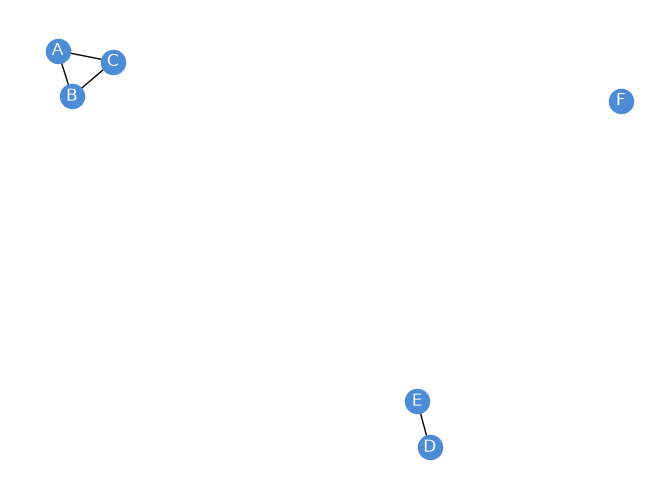

In [2]:
P = nx.Graph()
P.add_edges_from([("A", "B"), ("B", "C"), ("C", "A"), ("D", "E")])
P.add_node("F")                                   # a node with no edges

print("degrees:   ", dict(P.degree()))
print("components:", [sorted(c) for c in nx.connected_components(P)])
print("A->C path: ", nx.shortest_path(P, "A", "C"))
nx.draw(P, with_labels=True, node_color="#4c8bd6", font_color="white")
plt.show()

### 1b. Project: Glasgow companies ↔ addresses
Node IDs get a prefix so the kinds never clash: `C:` company, `A:` address. Every node also stores its `kind`.

In [3]:
gla = q("""-- glasgow_companies
SELECT CompanyNumber, address_key, risk_score, accounts_overdue
FROM risk_flags
WHERE postcode_area = 'G'
""")
print(len(gla), "Glasgow companies;", gla["address_key"].notna().sum(), "with an address key")

G = nx.Graph()
G.add_nodes_from(("C:" + gla["CompanyNumber"]).tolist(), kind="company")
with_addr = gla.dropna(subset=["address_key"])
G.add_nodes_from(("A:" + with_addr["address_key"]).unique().tolist(), kind="address")
G.add_edges_from(zip("C:" + with_addr["CompanyNumber"], "A:" + with_addr["address_key"]))

risk_of = dict(zip("C:" + gla["CompanyNumber"], gla["risk_score"]))      # node -> risk_score
print(f"nodes {G.number_of_nodes():,} · edges {G.number_of_edges():,}")

83681 Glasgow companies; 83680 with an address key
nodes 123,285 · edges 83,680


In [4]:
comps = sorted(nx.connected_components(G), key=len, reverse=True)
kind  = nx.get_node_attributes(G, "kind")

def n_kind(nodes, k):
    """How many nodes of kind k are in a set of nodes."""
    return sum(1 for n in nodes if kind[n] == k)

addr_deg = pd.Series({n: d for n, d in G.degree() if kind[n] == "address"})
summary = {
    "components":                      len(comps),
    "largest component: companies":    n_kind(comps[0], "company"),
    "largest component: addresses":    n_kind(comps[0], "address"),
    "addresses with 1 company":        int((addr_deg == 1).sum()),
    "addresses with 10+ companies":    int((addr_deg >= 10).sum()),
    "companies at 10+ company addresses": int(addr_deg[addr_deg >= 10].sum()),
}
pd.Series(summary)

components                            39605
largest component: companies           1614
largest component: addresses              1
addresses with 1 company              31139
addresses with 10+ companies            578
companies at 10+ company addresses    30892
dtype: int64

---
## Part 2 · Who is central? (Day 2)
**Degree centrality** = links / (n−1) · **Betweenness** = share of shortest paths through a node (bridges) · **PageRank** = linked to by important nodes (random surfer, d = 0.85).

### 2a. Practice: karate club, three centralities side by side

In [5]:
K = nx.karate_club_graph()
measures = {"degree": nx.degree_centrality(K),
            "betweenness": nx.betweenness_centrality(K),
            "pagerank": nx.pagerank(K)}
top5 = pd.DataFrame({name: [f"{n} ({v:.3f})" for n, v in sorted(d.items(), key=lambda x: -x[1])[:5]]
                     for name, d in measures.items()})
top5.index = range(1, 6)
top5

,degree,betweenness,pagerank
1,33 (0.515),0 (0.438),33 (0.097)
2,0 (0.485),33 (0.304),0 (0.089)
3,32 (0.364),32 (0.145),32 (0.076)
4,2 (0.303),2 (0.144),2 (0.063)
5,1 (0.273),31 (0.138),1 (0.057)


### 2b. Corporate owners: names + registration numbers (one-time load)
The `psc` table kept no names. This reads the PSC files once more, **corporate owners only**, and keeps the owner's name and registration number. The registration number is cleaned and padded to 8 characters (`'1234567'` → `'01234567'`) so it can match `CompanyNumber`.

This takes a few minutes the first time; after that, the table already exists and loading is skipped.

In [7]:
def looks_like_psc(path):
    """True if the file's first line is a PSC JSON record."""
    try:
        with open(path, encoding="utf-8") as fh:
            first = json.loads(fh.readline())
        return isinstance(first, dict) and "company_number" in first and "data" in first
    except Exception:
        return False

if "psc_corporate" not in set(q("SHOW TABLES")["name"]):
    psc_files = sorted(str(p) for p in PSC_DIR.rglob("*")
                       if p.suffix.lower() in (".txt", ".json") and p.stat().st_size > 0 and looks_like_psc(p))
    assert psc_files, "No PSC files found in data/raw/psc"
    file_list = "[" + ", ".join(f"'{f}'" for f in psc_files) + "]"
    corp_sql = """
CREATE OR REPLACE TABLE psc_corporate AS
WITH raw AS (
    SELECT company_number                                                         AS CompanyNumber,
           json_extract_string(data, '$.name')                                    AS owner_name,
           upper(regexp_replace(coalesce(json_extract_string(data, '$.identification.registration_number'), ''),
                                '[^A-Za-z0-9]', '', 'g'))                           AS reg_clean,
           upper(json_extract_string(data, '$.identification.country_registered')) AS country_registered
    FROM read_json(PSC_FILES, format = 'newline_delimited',
                   columns = {'company_number': 'VARCHAR', 'data': 'JSON'})
    WHERE company_number IS NOT NULL
      AND json_extract_string(data, '$.kind') LIKE 'corporate%'
      AND json_extract_string(data, '$.ceased_on') IS NULL)
SELECT CompanyNumber, owner_name, country_registered,
       CASE WHEN regexp_matches(reg_clean, '^[0-9]{1,8}$') THEN lpad(reg_clean, 8, '0')
            ELSE NULLIF(reg_clean, '') END AS owner_number
FROM raw;
"""
    (SQL_DIR / "05_psc_corporate.sql").write_text(corp_sql)        # placeholder kept, no local path
    t0 = time.perf_counter()
    con.execute(corp_sql.replace("PSC_FILES", file_list))
    print(f"psc_corporate built in {time.perf_counter() - t0:.0f} s")

q("""SELECT COUNT(*) AS corporate_psc_rows,
            COUNT(owner_number) AS with_reg_number,
            COUNT(*) FILTER (WHERE owner_number IN (SELECT CompanyNumber FROM clean_companies)) AS owner_in_register
     FROM psc_corporate""")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

psc_corporate built in 5 s


,corporate_psc_rows,with_reg_number,owner_in_register
0,847400,789188,645761


### 2c. Project: add owners to the Glasgow graph
- **People:** node `P:<hashed id>` (kind `person`). Never named.
- **Corporate owners in the live register:** node `C:<company number>`, so a company that owns another company is the **same node**.
- **Other corporate owners** (foreign, or not matched): node `O:<hash of name>` (kind `owner_company`); the name is kept only as an attribute, for the private hub table.

In [8]:
ind = q("""-- glasgow_individual_owners
SELECT a.CompanyNumber, a.ind_person_id
FROM psc_active a JOIN risk_flags r ON r.CompanyNumber = a.CompanyNumber
WHERE r.postcode_area = 'G' AND a.ind_person_id IS NOT NULL
""")
corp = q("""-- glasgow_corporate_owners
SELECT pc.CompanyNumber, pc.owner_name, pc.owner_number,
       c.CompanyNumber IS NOT NULL AS owner_in_register
FROM psc_corporate pc
JOIN risk_flags r ON r.CompanyNumber = pc.CompanyNumber
LEFT JOIN clean_companies c ON c.CompanyNumber = pc.owner_number
WHERE r.postcode_area = 'G'
""")

def name_hash(name):
    """Short stable ID from an owner name (upper case, md5, first 12 characters)."""
    return hashlib.md5(str(name).upper().strip().encode()).hexdigest()[:12]

G.add_nodes_from(("P:" + ind["ind_person_id"]).unique().tolist(), kind="person")
G.add_edges_from(zip("P:" + ind["ind_person_id"], "C:" + ind["CompanyNumber"]))

owner_label = {}                                     # node -> owner name (private use only)
for row in corp.itertuples(index=False):
    if row.owner_in_register:
        owner = "C:" + row.owner_number
        if owner not in G:
            G.add_node(owner, kind="company")         # a company outside Glasgow that owns a Glasgow company
    else:
        owner = "O:" + name_hash(row.owner_name)
        G.add_node(owner, kind="owner_company")
    owner_label[owner] = row.owner_name
    G.add_edge(owner, "C:" + row.CompanyNumber)

kind = nx.get_node_attributes(G, "kind")
print(f"nodes {G.number_of_nodes():,} · edges {G.number_of_edges():,}")
print(pd.Series(kind).value_counts())

nodes 195,459 · edges 181,637
company          85039
person           69964
address          39604
owner_company      852
Name: count, dtype: int64


In [9]:
t0 = time.perf_counter()
deg = dict(G.degree())
pr  = nx.pagerank(G, alpha=0.85)
print(f"degree + PageRank in {time.perf_counter() - t0:.1f} s")

RUN_BETWEENNESS = False          # slow on big graphs; True = estimate from k=200 random start nodes
btw = nx.betweenness_centrality(G, k=200, seed=42) if RUN_BETWEENNESS else {}

def label(n):
    """Readable name for a hub (addresses and companies only; people are never named)."""
    if n.startswith("A:"): return n[2:]
    if n.startswith("P:"): return "person " + n[2:10]
    return owner_label.get(n, n[2:])

hub_nodes = [n for n in G if kind[n] in ("address", "owner_company") or
             (kind[n] == "company" and n in owner_label)]
hubs = (pd.DataFrame({"node": hub_nodes,
                      "kind": [kind[n] for n in hub_nodes],
                      "degree": [deg[n] for n in hub_nodes],
                      "pagerank": [pr[n] for n in hub_nodes]})
          .assign(betweenness=lambda d: d["node"].map(btw) if btw else np.nan,
                  label=lambda d: d["node"].map(label))
          .sort_values("pagerank", ascending=False)
          .head(20)
          .reset_index(drop=True))
hubs.to_csv(RESULTS / "network_hubs.csv", index=False)       # PRIVATE: gitignored
hubs[["kind", "degree", "pagerank", "label"]]

degree + PageRank in 0.3 s


,kind,degree,pagerank,label
0,address,1614,0.002906,272 BATH STREET | G24JR
1,address,1099,0.002186,48 WEST GEORGE STREET | G21BP
2,address,1046,0.002112,CLYDE OFFICES 2ND FLOOR | G21BP
3,address,916,0.001594,6TH FLOOR GORDON CHAMBERS | G13NQ
4,address,817,0.001574,9 ROYAL CRESCENT | G37SP
5,address,898,0.001545,1 CAMBUSLANG COURT | G328FH
6,address,594,0.001021,HORIZON CA | G37LH
7,address,573,0.000972,OFFICE 1 | G413JA
8,address,499,0.000915,2ND FLOOR | G24BG
9,address,427,0.000868,CLYDE OFFICES | G21BP


---
## Part 3 · Ownership chains and cycles (Day 3)
Directed edge **owner company → owned company**. **Cycle** = the arrows loop back. **DAG** = no cycles. **SCC** (strongly connected component) = every node reaches every other following the arrows; every cycle lives inside an SCC of size ≥ 2.

### 3a. Practice: 7-company toy graph with one cycle

In [10]:
T = nx.DiGraph([("HoldCo", "B"), ("HoldCo", "C"), ("B", "D"), ("D", "E"), ("E", "B"), ("C", "F"), ("F", "G")])
print("cycles:", list(nx.simple_cycles(T)), "· DAG?", nx.is_directed_acyclic_graph(T))
T.remove_edge("E", "B")
print("after removing E->B: DAG?", nx.is_directed_acyclic_graph(T),
      "· longest chain:", nx.dag_longest_path(T), "· length", nx.dag_longest_path_length(T))

cycles: [['D', 'E', 'B']] · DAG? False
after removing E->B: DAG? True · longest chain: ['HoldCo', 'B', 'D', 'E'] · length 3


### 3b. Project: UK-wide ownership graph
Only owners that are themselves live UK companies (matched registration number), and only owned companies in the live register.

In [11]:
edges = q("""-- uk_ownership_edges
SELECT DISTINCT pc.owner_number AS owner, pc.CompanyNumber AS owned
FROM psc_corporate pc
JOIN clean_companies o ON o.CompanyNumber = pc.owner_number
JOIN clean_companies c ON c.CompanyNumber = pc.CompanyNumber
""")
D = nx.DiGraph()
D.add_edges_from(zip(edges["owner"], edges["owned"]))

self_owned = set(nx.nodes_with_selfloops(D))                  # company listed as its own owner
sccs = [s for s in nx.strongly_connected_components(D) if len(s) > 1]
in_cycle_nodes = set().union(*sccs) | self_owned if sccs else set(self_owned)
print(f"ownership graph: {D.number_of_nodes():,} companies, {D.number_of_edges():,} edges")
print(f"self-owned: {len(self_owned)} · SCCs with 2+ companies: {len(sccs)} · companies in a loop: {len(in_cycle_nodes)}")

ownership graph: 661,070 companies, 505,950 edges
self-owned: 188 · SCCs with 2+ companies: 554 · companies in a loop: 1352


In [12]:
def count_cycles(graph, max_len=10, cap=100_000):
    """Count simple cycles up to max_len links (stops at cap so huge tangles can't run forever)."""
    try:
        gen = nx.simple_cycles(graph, length_bound=max_len)
    except TypeError:                                   # older NetworkX without length_bound
        gen = nx.simple_cycles(graph)
    return sum(1 for _ in islice(gen, cap))

t0 = time.perf_counter()
n_cycles = sum(count_cycles(D.subgraph(s)) for s in sccs) + len(self_owned)
cycle_sizes = pd.Series([len(s) for s in sccs]).value_counts().sort_index()
print(f"cycles (≤10 links, incl. self-ownership): {n_cycles:,}  [{time.perf_counter() - t0:.1f} s]")
print("companies per loop group:\n", cycle_sizes.head(10))
pd.DataFrame({"metric": ["self_owned", "loop_groups", "companies_in_loops", "cycles_le_10_links"],
              "value": [len(self_owned), len(sccs), len(in_cycle_nodes), n_cycles]}
            ).to_csv(RESULTS / "ownership_cycles_summary.csv", index=False)

cycles (≤10 links, incl. self-ownership): 760  [0.0 s]
companies per loop group:
 2     520
3      24
4       7
5       2
14      1
Name: count, dtype: int64


**Chain depth with loops present:** squash each loop group (SCC) into one super-node. That's `nx.condensation`, and the result is always a DAG. Walk it in **topological order** (owners before owned): depth = 1 + the deepest owner's depth, and 0 for companies no registered company owns. `parent` remembers which owner gave the depth, so the chain can be rebuilt.

0     187875
1     303202
2      80042
3      33012
4      20338
5      12656
6       7789
7       5283
8       3243
9       2621
10      1867
11      1117
12       967
13       529
14       222
15        89
16       102
17        69
18        31
19         8
20         3
21         5
Name: count, dtype: int64


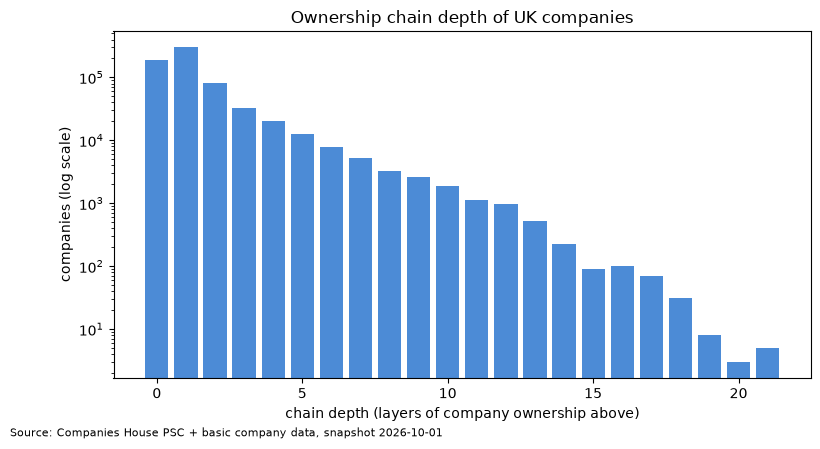

In [13]:
C = nx.condensation(D)                         # DAG of SCCs; C.graph["mapping"]: company -> super-node
mapping = C.graph["mapping"]
depth, parent = {}, {}
for n in nx.topological_sort(C):
    owners = list(C.predecessors(n))
    if owners:
        best = max(owners, key=lambda o: depth[o])
        depth[n], parent[n] = depth[best] + 1, best
    else:
        depth[n] = 0

chain_depth = {company: depth[s] for company, s in mapping.items()}
depth_counts = pd.Series(chain_depth).value_counts().sort_index()
print(depth_counts)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(depth_counts.index, depth_counts.values, color="#4c8bd6")
ax.set_yscale("log")
ax.set(xlabel="chain depth (layers of company ownership above)", ylabel="companies (log scale)",
       title="Ownership chain depth of UK companies")      # rewrite as the finding once you see the numbers
fig.text(0.01, -0.02, "Source: Companies House PSC + basic company data, snapshot 2026-10-01", fontsize=8)
fig.savefig(FIG / "net_chain_depth.png", dpi=200, bbox_inches="tight")
plt.show()

In [14]:
def chain_to(node):
    """Company numbers from the top owner down to this super-node (one member per loop group)."""
    path = [node]
    while path[-1] in parent:
        path.append(parent[path[-1]])
    return [min(C.nodes[s]["members"]) for s in reversed(path)]

deepest = sorted(depth, key=depth.get, reverse=True)[:10]
deep_chains = pd.DataFrame({"depth": [depth[s] for s in deepest],
                            "chain_top_to_bottom": [" > ".join(chain_to(s)) for s in deepest]})
deep_chains.to_csv(RESULTS / "ownership_deepest_chains.csv", index=False)
deep_chains

,depth,chain_top_to_bottom
0,21,02055886 > 14077050 > 14077056 > 14077054 > 12...
1,21,02055886 > 14077050 > 14077056 > 14077054 > 12...
2,21,02055886 > 14077050 > 14077056 > 14077054 > 12...
3,21,13353548 > 13665629 > 14076172 > 14084155 > 05...
4,21,13353548 > 13665629 > 14076172 > 14084155 > 05...
5,20,02055886 > 14077050 > 14077056 > 14077054 > 12...
6,20,02055886 > 14077050 > 14077056 > 14077054 > 12...
7,20,13353548 > 13665629 > 14076172 > 14084155 > 05...
8,19,02055886 > 14077050 > 14077056 > 14077054 > 12...
9,19,13353548 > 13665629 > 14076172 > 14084155 > 05...


---
## Part 4 · Communities and network pictures (Day 4)
**Louvain** keeps moving nodes between groups while **modularity Q** (edges inside groups minus what chance predicts) rises, then merges each group into a super-node and repeats. `seed=42` makes the result repeatable.

### 4a. Practice: Louvain on the karate club

4 communities · sizes [6, 10, 4, 14] · Q = 0.427


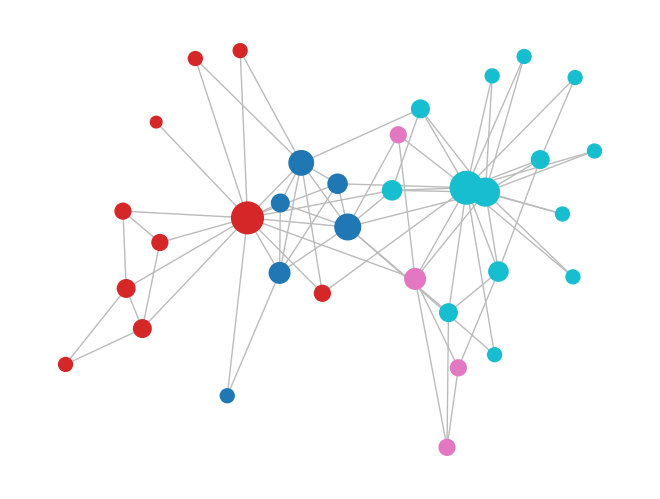

In [15]:
kc = nx.community.louvain_communities(K, seed=42)
print(len(kc), "communities · sizes", [len(c) for c in kc], "· Q =", round(nx.community.modularity(K, kc), 3))
comm_k = {n: i for i, c in enumerate(kc) for n in c}
pos_k = nx.spring_layout(K, seed=7)
nx.draw(K, pos_k, node_color=[comm_k[n] for n in K], cmap="tab10",
        node_size=[40 + 30 * d for _, d in K.degree()], edge_color="#bbbbbb")
plt.show()

### 4b. Project: Louvain on the Glasgow company–address–owner graph

In [16]:
t0 = time.perf_counter()
communities = nx.community.louvain_communities(G, seed=42)
comm_of = {n: i for i, c in enumerate(communities) for n in c}
print(f"{len(communities):,} communities in {time.perf_counter() - t0:.0f} s · "
      f"Q = {nx.community.modularity(G, communities):.3f}")

nodes = pd.DataFrame({"node": list(G)})
nodes["kind"]      = nodes["node"].map(kind)
nodes["community"] = nodes["node"].map(comm_of)
nodes["risk"]      = nodes["node"].map(risk_of)                        # Glasgow companies only
nodes["in_cycle"]  = nodes["node"].str[2:].isin(in_cycle_nodes) & (nodes["kind"] == "company")

comm_table = (nodes.groupby("community")
                   .agg(companies=("kind", lambda k: (k == "company").sum()),
                        addresses=("kind", lambda k: (k == "address").sum()),
                        owners=("kind", lambda k: k.isin(["person", "owner_company"]).sum()),
                        avg_risk_score=("risk", "mean"),
                        companies_in_loops=("in_cycle", "sum"))
                   .sort_values("companies", ascending=False))
comm_table.head(10).round(2).to_csv(RESULTS / "network_communities.csv")
comm_table.head(10).round(2)

32,745 communities in 5 s · Q = 0.994


,companies,addresses,owners,avg_risk_score,companies_in_loops
community,,,,,
19730,1666,17,581,2.81,0
20015,1282,87,1174,1.17,0
31012,1277,89,1091,1.17,0
31043,1174,56,1100,1.26,0
14645,1106,87,921,1.12,0
31245,902,41,816,1.19,0
20019,781,3,259,2.99,0
20045,722,32,508,1.35,0
23515,622,51,528,1.11,0


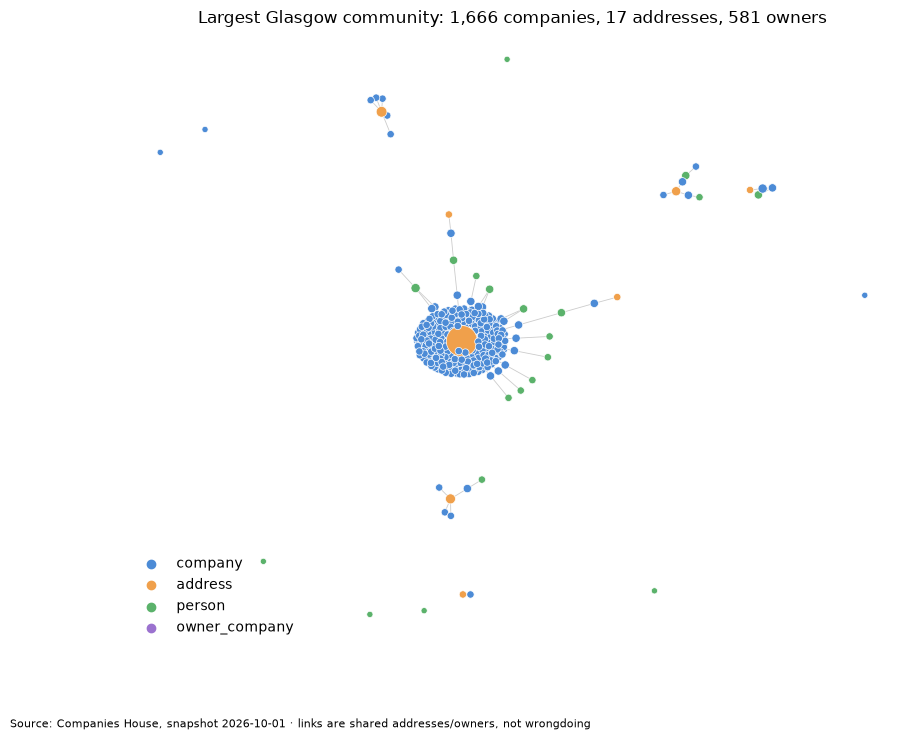

In [17]:
def draw_community(node_set, title, path, highlight=frozenset(), max_nodes=300):
    """Draw a community: size = degree, colour = kind, red ring = in an ownership loop, no labels."""
    sub = G.subgraph(node_set)
    if sub.number_of_nodes() > max_nodes:                  # keep it readable: the best-connected nodes
        keep = sorted(sub.degree, key=lambda x: -x[1])[:max_nodes]
        sub = G.subgraph([n for n, _ in keep])
    pos = nx.spring_layout(sub, seed=7, k=1 / np.sqrt(max(sub.number_of_nodes(), 1)))
    fig, ax = plt.subplots(figsize=(10, 8))
    nx.draw_networkx_edges(sub, pos, ax=ax, edge_color="#cccccc", width=0.6)
    nx.draw_networkx_nodes(sub, pos, ax=ax,
                           node_color=[KIND_COLORS[kind[n]] for n in sub],
                           node_size=[20 + 8 * min(sub.degree(n), 60) for n in sub],
                           edgecolors=["#d9534f" if n[2:] in highlight else "white" for n in sub],
                           linewidths=[2.5 if n[2:] in highlight else 0.5 for n in sub])
    for k, c in KIND_COLORS.items():
        ax.scatter([], [], color=c, label=k)
    if highlight:
        ax.scatter([], [], facecolors="white", edgecolors="#d9534f", linewidths=2.5, label="in ownership loop")
    ax.legend(loc="lower left", frameon=False)
    ax.set_title(title); ax.axis("off")
    fig.text(0.01, 0.01, "Source: Companies House, snapshot 2026-10-01 · links are shared addresses/owners, not wrongdoing",
             fontsize=8)
    fig.savefig(path, dpi=200, bbox_inches="tight")
    plt.show()

biggest = comm_table.index[0]
row = comm_table.loc[biggest]
draw_community(communities[biggest],
               f"Largest Glasgow community: {int(row.companies):,} companies, {int(row.addresses):,} addresses, "
               f"{int(row.owners):,} owners",
               FIG / "net_largest_community.png")

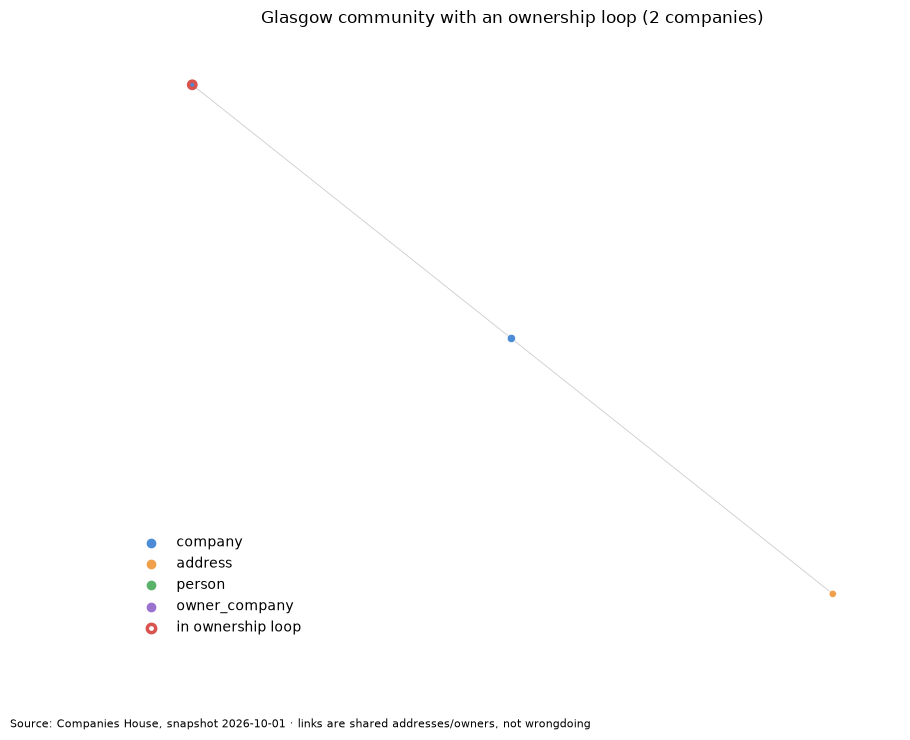

In [18]:
loop_comms = comm_table[comm_table["companies_in_loops"] > 0]
if len(loop_comms):
    cid = loop_comms["companies"].idxmin()                     # the smallest community with a loop is easiest to read
    draw_community(communities[cid],
                   f"Glasgow community with an ownership loop ({int(comm_table.loc[cid, 'companies'])} companies)",
                   FIG / "net_community_with_cycle.png", highlight=frozenset(in_cycle_nodes))
else:
    # no loop touches Glasgow: draw the smallest UK loop group plus its direct neighbours instead
    s = min(sccs, key=len)
    around = set(s) | {m for n in s for m in nx.all_neighbors(D, n)}
    sub = D.subgraph(around)
    fig, ax = plt.subplots(figsize=(8, 6))
    pos = nx.spring_layout(sub, seed=7)
    nx.draw_networkx(sub, pos, ax=ax, with_labels=False, arrowsize=15,
                     node_color=["#d9534f" if n in s else "#4c8bd6" for n in sub])
    ax.set_title(f"UK ownership loop: {len(s)} companies (red) and their direct owners/subsidiaries")
    ax.axis("off")
    fig.savefig(FIG / "net_community_with_cycle.png", dpi=200, bbox_inches="tight")
    plt.show()

---
## Part 5 · Network measures → columns (Day 5)
Each company gets its network measures as columns; the table is joined back to `risk_flags` (one row per company, so no fan-out).

| Column | From | Meaning |
|---|---|---|
| `network_degree` | Glasgow graph | links: its address + its owners + companies it owns |
| `pagerank` | Glasgow graph | importance in the Glasgow network |
| `community_id`, `community_companies` | Louvain | which group, and how many companies are in it |
| `community_risk` | Louvain + risk_flags | average `risk_score` of the companies in its community |
| `in_cycle` | UK ownership graph | 1 if part of an ownership loop (or owns itself) |
| `chain_depth` | UK ownership graph | layers of company ownership above it (0 = none) |

Glasgow measures are NULL outside Glasgow; the ownership measures cover the whole UK.

In [19]:
comp_nodes = [n for n in G if kind[n] == "company" and n in risk_of]        # Glasgow companies
comm_companies = comm_table["companies"]
comm_risk      = comm_table["avg_risk_score"]

gla_feat = pd.DataFrame({
    "CompanyNumber":       [n[2:] for n in comp_nodes],
    "network_degree":      [deg[n] for n in comp_nodes],
    "pagerank":            [pr[n] for n in comp_nodes],
    "community_id":        [comm_of[n] for n in comp_nodes],
})
gla_feat["community_companies"] = gla_feat["community_id"].map(comm_companies)
gla_feat["community_risk"]      = gla_feat["community_id"].map(comm_risk)

uk_feat = pd.DataFrame({"CompanyNumber": list(chain_depth),
                        "chain_depth": list(chain_depth.values())})
uk_feat["in_cycle"] = uk_feat["CompanyNumber"].isin(in_cycle_nodes).astype(int)

network_features = gla_feat.merge(uk_feat, on="CompanyNumber", how="outer")
print(len(network_features), "companies with at least one network measure")
assert network_features["CompanyNumber"].is_unique
network_features.head()

735730 companies with at least one network measure


,CompanyNumber,network_degree,pagerank,community_id,community_companies,community_risk,chain_depth,in_cycle
0,00000086,NaN,NaN,NaN,NaN,NaN,3.0,0.0
1,00000118,NaN,NaN,NaN,NaN,NaN,0.0,0.0
2,00000133,NaN,NaN,NaN,NaN,NaN,1.0,0.0
3,00000140,NaN,NaN,NaN,NaN,NaN,1.0,0.0
4,00000529,NaN,NaN,NaN,NaN,NaN,3.0,0.0


In [20]:
con.register("network_features_df", network_features)          # lets SQL read the DataFrame
con.execute("CREATE OR REPLACE TABLE network_features AS SELECT * FROM network_features_df")
con.unregister("network_features_df")

con.execute("""
CREATE OR REPLACE TABLE risk_flags_network AS
SELECT r.*,
       n.network_degree, n.pagerank, n.community_id, n.community_companies, n.community_risk,
       COALESCE(n.in_cycle, 0)    AS in_cycle,
       COALESCE(n.chain_depth, 0) AS chain_depth
FROM risk_flags r
LEFT JOIN network_features n USING (CompanyNumber)
""")
q("SELECT COUNT(*) AS rows, COUNT(DISTINCT CompanyNumber) AS companies, SUM(in_cycle) AS in_cycle, COUNT(pagerank) AS glasgow_rows FROM risk_flags_network")

,rows,companies,in_cycle,glasgow_rows
0,5704711,5704711,1352.0,83681


### 5b. Findings: does the network add information?

In [21]:
# 1) Companies in ownership loops vs the rest (UK)
q("""SELECT in_cycle, COUNT(*) AS n,
            round(AVG(risk_score), 3)             AS avg_risk_score,
            round(100 * AVG(accounts_overdue), 2) AS accounts_overdue_pct,
            round(100 * AVG(no_psc_named), 2)     AS no_psc_named_pct
     FROM risk_flags_network GROUP BY in_cycle ORDER BY in_cycle DESC""")

,in_cycle,n,avg_risk_score,accounts_overdue_pct,no_psc_named_pct
0,1.0,1352,1.459,4.44,0.00
1,0.0,5703359,0.795,7.73,7.83


In [22]:
# 2) Chain depth bands (UK)
q("""SELECT CASE WHEN chain_depth = 0 THEN '0 (no company owner)' WHEN chain_depth = 1 THEN '1'
                 WHEN chain_depth <= 3 THEN '2-3' ELSE '4+' END AS depth_band,
            COUNT(*) AS n, round(AVG(risk_score), 3) AS avg_risk_score,
            round(100 * AVG(accounts_overdue), 2) AS accounts_overdue_pct
     FROM risk_flags_network GROUP BY depth_band ORDER BY depth_band""")

,depth_band,n,avg_risk_score,accounts_overdue_pct
0,0 (no company owner),5231516,0.714,7.80
1,1,303202,1.609,5.50
2,2-3,113054,1.768,8.22
3,4+,56939,1.921,11.47


In [23]:
# 3) Glasgow: do central companies carry more risk? (Spearman = rank correlation, robust to skew)
gla_net = q("""SELECT pagerank, network_degree, community_risk, risk_score
               FROM risk_flags_network WHERE pagerank IS NOT NULL""")
print(gla_net.corr(method="spearman")["risk_score"].round(3))

# 4) Glasgow communities with 20+ companies, ranked by average risk
comm_table[comm_table["companies"] >= 20].sort_values("avg_risk_score", ascending=False).head(10).round(2)

pagerank         -0.436
network_degree   -0.193
community_risk    0.821
risk_score        1.000
Name: risk_score, dtype: float64


,companies,addresses,owners,avg_risk_score,companies_in_loops
community,,,,,
32700,24,1,0,3.83,0
20640,22,1,0,3.82,0
21448,38,1,0,3.08,0
20019,781,3,259,2.99,0
20244,45,1,21,2.93,0
23470,37,3,35,2.92,0
20158,36,1,8,2.86,0
32666,155,2,88,2.84,0
19730,1666,17,581,2.81,0


### 5c. Export + README section

In [24]:
RFN = ROOT / "data" / "processed" / "risk_flags_network.parquet"
con.execute(f"COPY risk_flags_network TO '{RFN}' (FORMAT parquet)")
print("exported:", RFN.relative_to(ROOT))

section = """## Ownership network

**Method.** Glasgow (postcode area G): a graph of companies, their registered addresses and their owners (PSCs; people only as hashed IDs). UK-wide: a directed graph of company → company ownership from corporate PSC records. Measures: degree, PageRank, Louvain communities, ownership loops (strongly connected components) and chain depth (longest path in the condensed DAG). Notebook: `notebooks/08_network.ipynb`.

**Findings** (fill in with numbers):
1. Shared addresses: _… of … Glasgow companies sit in one large connected group; … addresses host 10+ companies._
2. Ownership loops: _… UK companies are in ownership loops; their average risk score is … vs … for the rest._
3. Communities: _the riskiest Glasgow community (20+ companies) averages … flags vs … for Glasgow overall._

![Largest Glasgow community](reports/figures/net_largest_community.png)
![Ownership loop](reports/figures/net_community_with_cycle.png)

**Caveat.** Network links show shared addresses or owners, not wrongdoing: formation agents legitimately register thousands of companies at one address, and group structures legitimately create chains. Live register only (dissolved companies missing); people matched by name + birth month, which can merge different people.
"""
(ROOT / "docs").mkdir(exist_ok=True)
(ROOT / "docs" / "README_network_section.md").write_text(section)
print(section)

exported: data/processed/risk_flags_network.parquet
## Ownership network

**Method.** Glasgow (postcode area G): a graph of companies, their registered addresses and their owners (PSCs; people only as hashed IDs). UK-wide: a directed graph of company → company ownership from corporate PSC records. Measures: degree, PageRank, Louvain communities, ownership loops (strongly connected components) and chain depth (longest path in the condensed DAG). Notebook: `notebooks/08_network.ipynb`.

**Findings** (fill in with numbers):
1. Shared addresses: _… of … Glasgow companies sit in one large connected group; … addresses host 10+ companies._
2. Ownership loops: _… UK companies are in ownership loops; their average risk score is … vs … for the rest._
3. Communities: _the riskiest Glasgow community (20+ companies) averages … flags vs … for Glasgow overall._

![Largest Glasgow community](reports/figures/net_largest_community.png)
![Ownership loop](reports/figures/net_community_with_cycle.png)

**C

---
## Findings (fill in)
- **Day 1:** …
- **Day 2:** top hubs are … (addresses / corporate owners).
- **Day 3:** … companies in loops; deepest chain … layers.
- **Day 4:** … communities, Q = …; riskiest community …
- **Day 5:** in-loop companies vs others: …; PageRank vs risk correlation: …

## Caveats
- Links are shared addresses or owners, **not wrongdoing**; formation agents legitimately host thousands of companies.
- Glasgow-only for the company–address–owner graph; ownership loops and depth are UK-wide.
- Corporate owners are matched on registration number; foreign or badly formatted numbers stay unmatched.
- Live register only (survivorship). People are a name + birth-month proxy.

## Interview check (30 seconds each)
- **PageRank:** imagine someone clicking random links forever, sometimes jumping anywhere. PageRank is how often they land on a node, so a node scores highly when well-connected nodes link to it.
- **Betweenness:** for every pair of nodes, take the shortest route between them. Betweenness is how often a node sits on those routes: high means a bridge whose removal splits the network.

In [25]:
con.close()   # release the database lock

**Terminal: commit** (names and addresses stay private)
```bash
cd /Users/shraddha/Documents/DATA_SCIENCE/Shellscope/shellscope
for f in results/network_hubs.csv results/network_communities.csv results/ownership_deepest_chains.csv; do
  grep -qx "$f" .gitignore || echo "$f" >> .gitignore
done
git add .gitignore notebooks/08_network.ipynb sql/05_psc_corporate.sql results/ownership_cycles_summary.csv \
        reports/figures/net_chain_depth.png reports/figures/net_largest_community.png \
        reports/figures/net_community_with_cycle.png docs/README_network_section.md README.md
git status
git commit -m "Ownership network: Glasgow graph, centrality, ownership loops, communities, network features"
git push
```